# Training
Model dilatih pada GPU Kaggle. Tiga eksperimen dibandingkan, kemudian dua model terbaik digabung (ensemble).

| Eksperimen | Model | Ukuran input (tinggi x lebar) | Perubahan |
|---|---|---|---|
| 1 | ResNet-18 | 224 x 224 | baseline |
| 2 | ConvNeXt-Tiny | 384 x 384 | arsitektur lebih modern, resolusi lebih tinggi |
| 3 | ConvNeXt-Tiny | 512 x 384 | mengikuti rasio halaman (± 1,31), resolusi vertikal lebih tinggi, regularisasi stochastic depth |
| ensemble | 2 + 3 | - | rata-rata probabilitas |

Alur pengerjaan mengikuti praktikum: Dataset & Dataloader → Arsitektur & Config → Training Preparation (MCOC) → Training → Evaluate → Predict.

# **Import Dataset & Script**
Dataset kompetisi dipasang melalui menu *Add Input* Kaggle. Script (`src/`) diambil dengan meng-clone repository ini.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/Violita-archive/document-image-classification.git"
REPO_NAME = "document-image-classification"

if Path("/kaggle/working").exists():
    ROOT = Path("/kaggle/working") / REPO_NAME
    if ROOT.exists():
        subprocess.run(["git", "-C", str(ROOT), "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    try:
        import timm
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Root:", ROOT)

Root: /kaggle/working/document-image-classification


# **Import Library**

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn, optim

from src.callback import Callback
from src.dataset import clean_train_data, load_metadata, make_loader, split_train_val
from src.model import count_parameters, load_checkpoint, model_from_config
from src.predict import predict_test, save_submission, validate_submission
from src.train import build_scheduler, loop_fn
from src.transforms import denormalize, get_eval_transforms, get_train_transforms, to_hw
from src.utils import CLASS_NAMES, ensure_dirs, get_device, load_config, resolve_data_dir, set_seed

FIG_DIR, METRIC_DIR, SUB_DIR = Path("results/figures"), Path("results/metrics"), Path("results/submissions")
ensure_dirs(FIG_DIR, METRIC_DIR, SUB_DIR, "checkpoint")

device = get_device()
print("PyTorch", torch.__version__, "| device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

PyTorch 2.11.0+cu128 | device: cuda | Tesla T4


# **Dataset & Dataloader**
Pembersihan mengikuti hasil EDA: file yang tidak dapat dibuka dan grup gambar identik berlabel berbeda dibuang, sedangkan duplikat berlabel sama disisakan satu. Data bersih dibagi 90% train dan 10% validation secara stratified. Pembagian yang sama dipakai untuk semua eksperimen. DataLoader dibuat pada tiap eksperimen karena ukuran input dan batch berbeda.

In [3]:
DATA_DIR = resolve_data_dir("data")
print("Folder data:", DATA_DIR)

train_full, test_df = load_metadata(DATA_DIR)
clean_df, clean_summary = clean_train_data(train_full, n_workers=8)
display(pd.Series(clean_summary, name="jumlah").to_frame().T)

tr_df, va_df = split_train_val(clean_df, val_size=0.1, seed=42)
print(f"train: {len(tr_df):,} | validation: {len(va_df):,} | test: {len(test_df):,}")
display(pd.DataFrame({"train": tr_df["class_name"].value_counts(), "validation": va_df["class_name"].value_counts()}).reindex(CLASS_NAMES).T)

label2cat = CLASS_NAMES

Folder data: /kaggle/input/competitions/document-image-classification-sd234504


Cek file:   0%|          | 0/32003 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))


,awal,tidak_terbaca,duplikat_label_bertentangan,duplikat_label_sama,akhir
jumlah,32003,1,43,8,31951


train: 28,755 | validation: 3,196 | test: 7,994


class_name,advertisement,budget,email,file_folder,form,handwritten,invoice,letter,memo,news_article,presentation,questionnaire,resume,scientific_publication,scientific_report,specification
train,1786,1803,1812,1819,1804,1823,1784,1775,1794,1766,1788,1750,1825,1849,1797,1780
validation,198,201,201,202,200,203,198,197,199,196,199,195,203,206,200,198


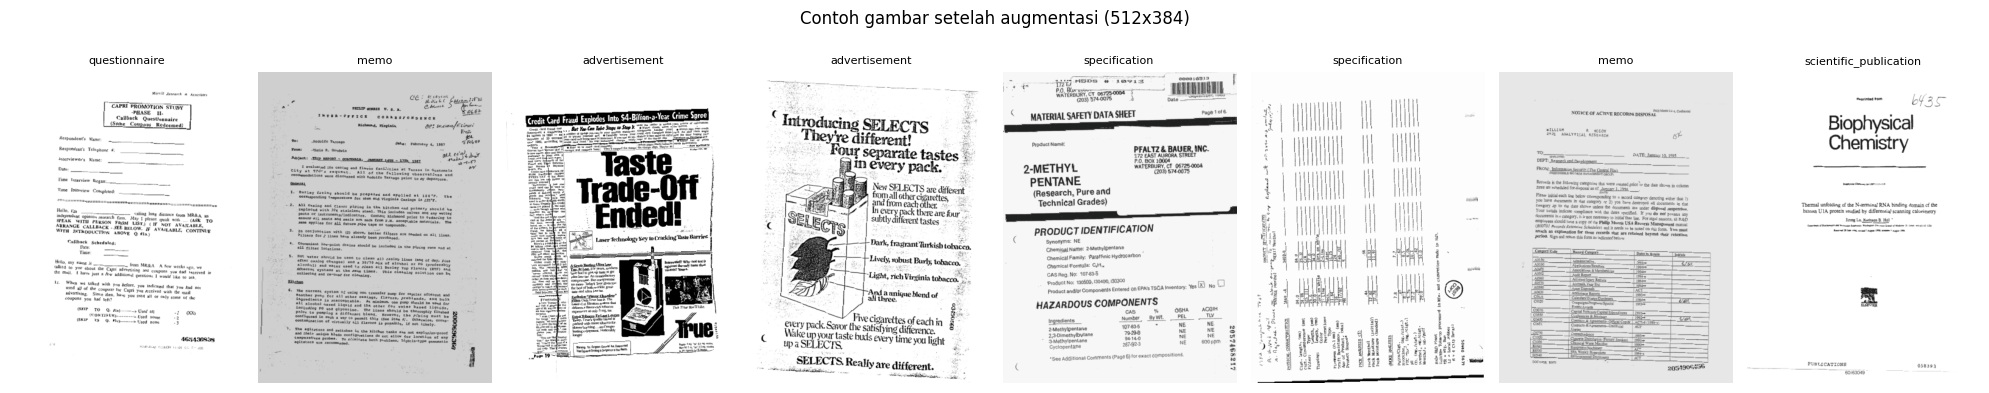

In [4]:
aug_loader = make_loader(tr_df.sample(8, random_state=1), get_train_transforms([512, 384]), 8, False, 0)
x, y = next(iter(aug_loader))
fig, axes = plt.subplots(1, 8, figsize=(20, 4.2))
for ax, img, lab in zip(axes, x, y):
    ax.imshow(denormalize(img))
    ax.set_title(CLASS_NAMES[lab], fontsize=8)
    ax.axis("off")
h, w = to_hw([512, 384])
plt.suptitle(f"Contoh gambar setelah augmentasi ({h}x{w})")
plt.tight_layout()
plt.savefig(FIG_DIR / "train_augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

# **Arsitektur & Config**
Model dibungkus dalam class `DocumentClassifier` (`src/model.py`). Backbone CNN diambil dari `timm` dengan bobot pre-trained ImageNet, lalu lapisan klasifikasi diganti menjadi 16 kelas. Seluruh lapisan di-fine-tune sejak awal, tanpa tahap freeze, karena citra dokumen cukup berbeda dengan citra alami pada ImageNet.

Konfigurasi tiap eksperimen disimpan dalam file YAML di folder `configs/` agar mudah direproduksi.

In [5]:
EXPERIMENTS = {
    "baseline_resnet18": "configs/baseline.yaml",
    "convnext_tiny_384": "configs/convnext_384.yaml",
    "convnext_tiny_512": "configs/config.yaml",
}
configs = {name: load_config(path) for name, path in EXPERIMENTS.items()}
display(pd.DataFrame(configs).T)

outs = {}

,data_dir,model_name,pretrained,num_classes,img_size,batch_size,epochs,lr,weight_decay,warmup_epochs,label_smoothing,drop_rate,patience,val_size,seed,num_workers,amp,drop_path_rate
baseline_resnet18,data,resnet18,True,16,224,64,5,0.0005,0.0001,1,0.0,0.0,3,0.1,42,4,True,NaN
convnext_tiny_384,data,convnext_tiny,True,16,384,32,10,0.0002,0.05,1,0.1,0.2,3,0.1,42,4,True,NaN
convnext_tiny_512,data,convnext_tiny,True,16,"[512, 384]",24,12,0.00015,0.05,1,0.1,0.2,3,0.1,42,4,True,0.2


# **Eksperimen 1: Baseline ResNet-18 (224 x 224)**

### Training Preparation (MCOC)

In [6]:
cfg = configs["baseline_resnet18"]
set_seed(cfg["seed"])
use_amp = bool(cfg["amp"]) and device.type == "cuda"

trainloader = make_loader(tr_df, get_train_transforms(cfg["img_size"]), cfg["batch_size"], True, cfg["num_workers"])
testloader = make_loader(va_df, get_eval_transforms(cfg["img_size"]), cfg["batch_size"] * 2, False, cfg["num_workers"])

model = model_from_config(cfg).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
optimizer = optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
scheduler = build_scheduler(optimizer, cfg["epochs"] * len(trainloader), cfg["warmup_epochs"] * len(trainloader))
scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
callback = Callback(model, cfg, exp_name="baseline_resnet18", patience=cfg["patience"])
print(f"{cfg['model_name']} | {count_parameters(model) / 1e6:.1f} juta parameter | input {to_hw(cfg['img_size'])} | AMP {use_amp}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

resnet18 | 11.2 juta parameter | input (224, 224) | AMP True


### Training

train:   0%|          | 0/450 [00:00<?, ?it/s]

/kaggle/working/document-image-classification/src/train.py:88: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


test:   0%|          | 0/25 [00:00<?, ?it/s]

epoch  1 | train loss 1.9395 acc 0.4185 | val loss 1.2462 acc 0.6217 | 158s *


train:   0%|          | 0/450 [00:00<?, ?it/s]

test:   0%|          | 0/25 [00:00<?, ?it/s]

... (6 outputs left out)

epoch  4 | train loss 0.5429 acc 0.8367 | val loss 0.6005 acc 0.8263 | 156s *


train:   0%|          | 0/450 [00:00<?, ?it/s]

test:   0%|          | 0/25 [00:00<?, ?it/s]

epoch  5 | train loss 0.4809 acc 0.8565 | val loss 0.5861 acc 0.8285 | 154s *


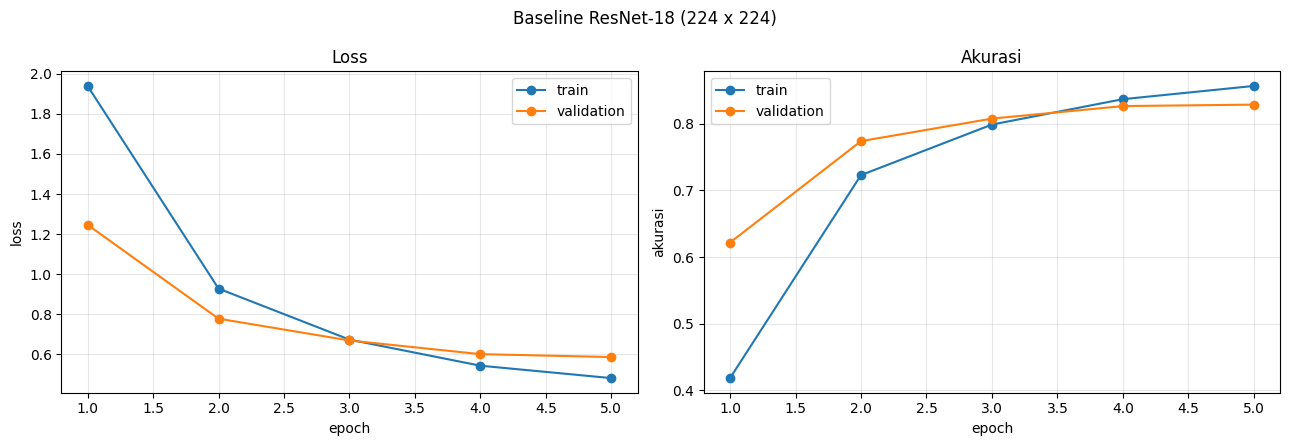

Akurasi validation terbaik: 0.8285 (epoch 5), waktu 13.0 menit


In [7]:
for epoch in range(cfg["epochs"]):
    train_cost, train_score, _ = loop_fn("train", trainloader, model, criterion, optimizer, device, scheduler, scaler, use_amp)
    with torch.no_grad():
        test_cost, test_score, test_probs = loop_fn("test", testloader, model, criterion, optimizer, device, use_amp=use_amp)

    callback.log(train_cost, test_cost, train_score, test_score, optimizer.param_groups[0]["lr"])
    if callback.early_stopping(model, test_score, test_probs):
        break

callback.plot_final("Baseline ResNet-18 (224 x 224)", FIG_DIR / "curve_baseline_resnet18.png")
outs["baseline_resnet18"] = callback.summary()
print(f"Akurasi validation terbaik: {callback.best_score:.4f} (epoch {callback.best_epoch}), waktu {outs['baseline_resnet18']['minutes']:.1f} menit")
del model, optimizer, scaler
torch.cuda.empty_cache()

# **Eksperimen 2: ConvNeXt-Tiny (384 x 384)**

### Training Preparation (MCOC)

In [8]:
cfg = configs["convnext_tiny_384"]
set_seed(cfg["seed"])
use_amp = bool(cfg["amp"]) and device.type == "cuda"

trainloader = make_loader(tr_df, get_train_transforms(cfg["img_size"]), cfg["batch_size"], True, cfg["num_workers"])
testloader = make_loader(va_df, get_eval_transforms(cfg["img_size"]), cfg["batch_size"] * 2, False, cfg["num_workers"])

model = model_from_config(cfg).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
optimizer = optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
scheduler = build_scheduler(optimizer, cfg["epochs"] * len(trainloader), cfg["warmup_epochs"] * len(trainloader))
scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
callback = Callback(model, cfg, exp_name="convnext_tiny_384", patience=cfg["patience"])
print(f"{cfg['model_name']} | {count_parameters(model) / 1e6:.1f} juta parameter | input {to_hw(cfg['img_size'])} | AMP {use_amp}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

convnext_tiny | 27.8 juta parameter | input (384, 384) | AMP True


### Training

train:   0%|          | 0/899 [00:00<?, ?it/s]

test:   0%|          | 0/50 [00:00<?, ?it/s]

epoch  1 | train loss 1.5164 acc 0.6409 | val loss 1.1638 acc 0.7791 | 447s *


train:   0%|          | 0/899 [00:00<?, ?it/s]

test:   0%|          | 0/50 [00:00<?, ?it/s]

epoch  2 | train loss 1.1117 acc 0.8010 | val loss 1.0440 acc 0.8348 | 408s *


... (20 outputs left out)

epoch  9 | train loss 0.6046 acc 0.9914 | val loss 0.8972 acc 0.8867 | 406s *


train:   0%|          | 0/899 [00:00<?, ?it/s]

test:   0%|          | 0/50 [00:00<?, ?it/s]

epoch 10 | train loss 0.5953 acc 0.9949 | val loss 0.8953 acc 0.8861 | 411s


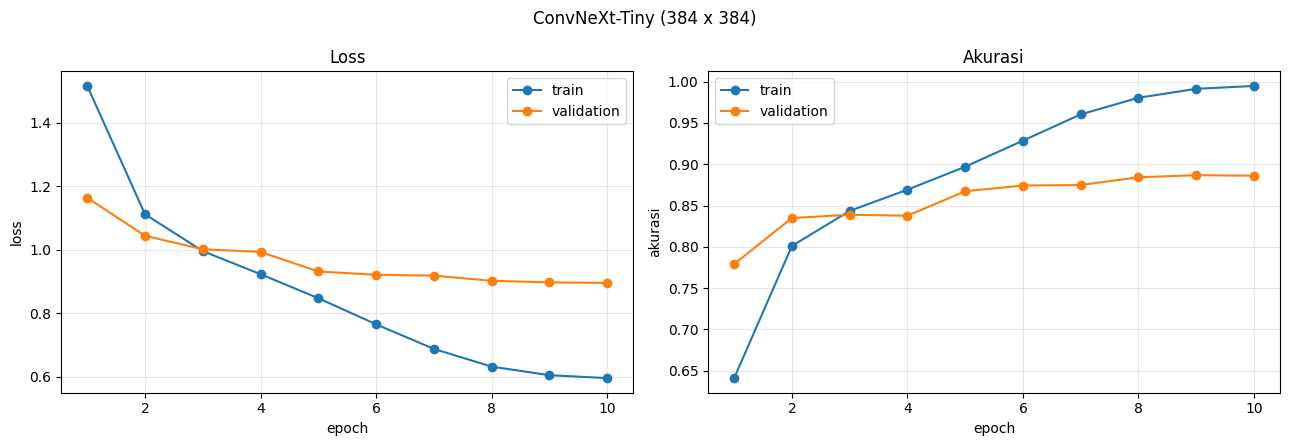

Akurasi validation terbaik: 0.8867 (epoch 9), waktu 68.7 menit


In [9]:
for epoch in range(cfg["epochs"]):
    train_cost, train_score, _ = loop_fn("train", trainloader, model, criterion, optimizer, device, scheduler, scaler, use_amp)
    with torch.no_grad():
        test_cost, test_score, test_probs = loop_fn("test", testloader, model, criterion, optimizer, device, use_amp=use_amp)

    callback.log(train_cost, test_cost, train_score, test_score, optimizer.param_groups[0]["lr"])
    if callback.early_stopping(model, test_score, test_probs):
        break

callback.plot_final("ConvNeXt-Tiny (384 x 384)", FIG_DIR / "curve_convnext_tiny_384.png")
outs["convnext_tiny_384"] = callback.summary()
print(f"Akurasi validation terbaik: {callback.best_score:.4f} (epoch {callback.best_epoch}), waktu {outs['convnext_tiny_384']['minutes']:.1f} menit")
del model, optimizer, scaler
torch.cuda.empty_cache()

# **Eksperimen 3: ConvNeXt-Tiny (512 x 384)**
Pada eksperimen 2 akurasi train mencapai ±99% sedangkan validation ±89%, sehingga model cenderung overfitting. Pada eksperimen ini ditambahkan stochastic depth (`drop_path_rate` 0,2). Ukuran input diubah menjadi 512 x 384 agar sesuai rasio halaman, sehingga teks tidak terlalu terdistorsi dan resolusi vertikal lebih tinggi.

### Training Preparation (MCOC)

In [10]:
cfg = configs["convnext_tiny_512"]
set_seed(cfg["seed"])
use_amp = bool(cfg["amp"]) and device.type == "cuda"

trainloader = make_loader(tr_df, get_train_transforms(cfg["img_size"]), cfg["batch_size"], True, cfg["num_workers"])
testloader = make_loader(va_df, get_eval_transforms(cfg["img_size"]), cfg["batch_size"] * 2, False, cfg["num_workers"])

model = model_from_config(cfg).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
optimizer = optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
scheduler = build_scheduler(optimizer, cfg["epochs"] * len(trainloader), cfg["warmup_epochs"] * len(trainloader))
scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
callback = Callback(model, cfg, exp_name="convnext_tiny_512", patience=cfg["patience"])
print(f"{cfg['model_name']} | {count_parameters(model) / 1e6:.1f} juta parameter | input {to_hw(cfg['img_size'])} | AMP {use_amp}")

convnext_tiny | 27.8 juta parameter | input (512, 384) | AMP True


### Training

train:   0%|          | 0/1199 [00:00<?, ?it/s]

test:   0%|          | 0/67 [00:00<?, ?it/s]

epoch  1 | train loss 1.6826 acc 0.5747 | val loss 1.2498 acc 0.7547 | 583s *


train:   0%|          | 0/1199 [00:00<?, ?it/s]

test:   0%|          | 0/67 [00:00<?, ?it/s]

epoch  2 | train loss 1.1926 acc 0.7712 | val loss 1.0750 acc 0.8201 | 548s *


... (26 outputs left out)

epoch 11 | train loss 0.6425 acc 0.9791 | val loss 0.9168 acc 0.8833 | 549s *


train:   0%|          | 0/1199 [00:00<?, ?it/s]

test:   0%|          | 0/67 [00:00<?, ?it/s]

epoch 12 | train loss 0.6335 acc 0.9830 | val loss 0.9155 acc 0.8833 | 552s


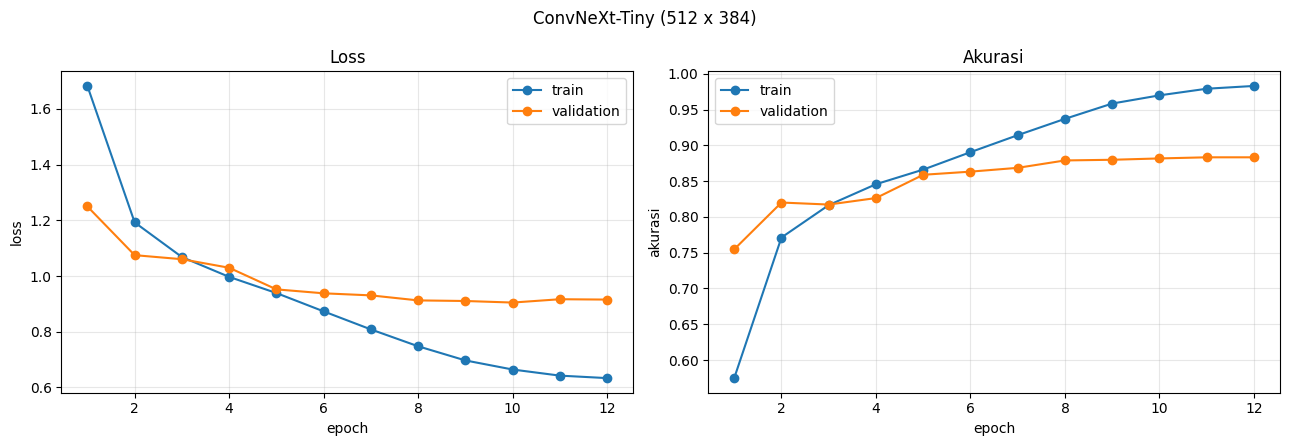

Akurasi validation terbaik: 0.8833 (epoch 11), waktu 110.3 menit


In [11]:
for epoch in range(cfg["epochs"]):
    train_cost, train_score, _ = loop_fn("train", trainloader, model, criterion, optimizer, device, scheduler, scaler, use_amp)
    with torch.no_grad():
        test_cost, test_score, test_probs = loop_fn("test", testloader, model, criterion, optimizer, device, use_amp=use_amp)

    callback.log(train_cost, test_cost, train_score, test_score, optimizer.param_groups[0]["lr"])
    if callback.early_stopping(model, test_score, test_probs):
        break

callback.plot_final("ConvNeXt-Tiny (512 x 384)", FIG_DIR / "curve_convnext_tiny_512.png")
outs["convnext_tiny_512"] = callback.summary()
print(f"Akurasi validation terbaik: {callback.best_score:.4f} (epoch {callback.best_epoch}), waktu {outs['convnext_tiny_512']['minutes']:.1f} menit")
del model, optimizer, scaler
torch.cuda.empty_cache()

# **Evaluate**
## Ensemble
Probabilitas eksperimen 2 dan 3 dirata-ratakan. Kedua model melihat gambar pada ukuran yang berbeda, sehingga kesalahannya diharapkan tidak selalu sama.

In [12]:
ENSEMBLE = ["convnext_tiny_384", "convnext_tiny_512"]
y_val = va_df["label"].values
ens_val = np.mean([outs[n]["val_probs"] for n in ENSEMBLE], axis=0)
ens_acc = (ens_val.argmax(1) == y_val).mean()

p2, p3 = (outs[n]["val_probs"].argmax(1) for n in ENSEMBLE)
print(f"Prediksi eksperimen 2 dan 3 berbeda pada {(p2 != p3).mean() * 100:.1f}% data validation")
print(f"Akurasi validation ensemble: {ens_acc:.4f}")

Prediksi eksperimen 2 dan 3 berbeda pada 7.4% data validation
Akurasi validation ensemble: 0.8924


## Perbandingan eksperimen

,eksperimen,model,input,epoch_dijalankan,epoch_terbaik,train_acc,val_acc,val_loss,selisih_train_val,menit
0,baseline_resnet18,resnet18,224x224,5.0,5.0,0.856547,0.828536,0.586071,0.028011,12.985103
1,convnext_tiny_384,convnext_tiny,384x384,10.0,9.0,0.991375,0.886733,0.897150,0.104642,68.708342
2,convnext_tiny_512,convnext_tiny,512x384,12.0,11.0,0.979134,0.883292,0.916774,0.095842,110.312590
3,ensemble,convnext_tiny_384 + convnext_tiny_512,-,NaN,NaN,NaN,0.892365,NaN,NaN,179.020932


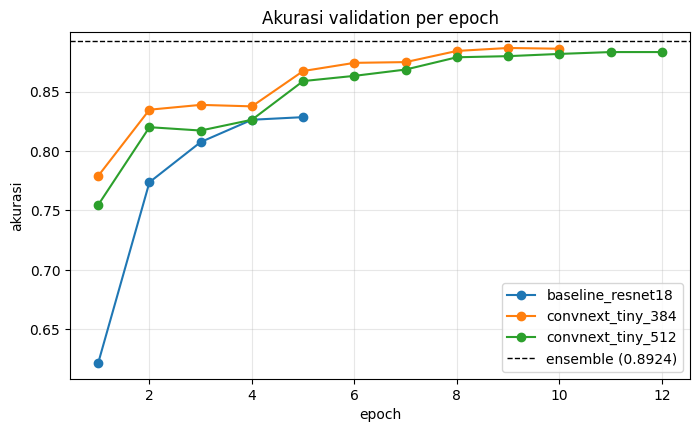

In [13]:
rows = []
for name, out in outs.items():
    cfg, h = configs[name], out["history"]
    best = h.loc[h["epoch"] == out["best_epoch"]].iloc[0]
    hh, ww = to_hw(cfg["img_size"])
    rows.append({"eksperimen": name, "model": cfg["model_name"], "input": f"{hh}x{ww}", "epoch_dijalankan": len(h),
                 "epoch_terbaik": out["best_epoch"], "train_acc": best["train_acc"], "val_acc": out["best_acc"],
                 "val_loss": best["val_loss"], "selisih_train_val": best["train_acc"] - out["best_acc"], "menit": out["minutes"]})
rows.append({"eksperimen": "ensemble", "model": " + ".join(ENSEMBLE), "input": "-", "val_acc": ens_acc,
             "menit": sum(outs[n]["minutes"] for n in ENSEMBLE)})
experiments = pd.DataFrame(rows)
experiments.to_csv(METRIC_DIR / "experiments.csv", index=False)
display(experiments)

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, out in outs.items():
    ax.plot(out["history"]["epoch"], out["history"]["val_acc"], marker="o", label=name)
ax.axhline(ens_acc, color="black", ls="--", lw=1, label=f"ensemble ({ens_acc:.4f})")
ax.set(title="Akurasi validation per epoch", xlabel="epoch", ylabel="akurasi")
ax.grid(alpha=0.3)
ax.legend()
plt.savefig(FIG_DIR / "experiments_val_acc.png", dpi=150, bbox_inches="tight")
plt.show()

## Prediksi validation
Probabilitas tiap model dan ensemble disimpan untuk analisis lanjutan di `03_evaluation.ipynb`.

In [14]:
val_probs = {name: out["val_probs"] for name, out in outs.items()}
val_probs["ensemble"] = ens_val
for name, probs in val_probs.items():
    pred_df = va_df[["id", "filename", "label"]].copy()
    pred_df["pred"] = probs.argmax(1)
    pred_df["confidence"] = probs.max(1)
    pred_df[[f"prob_{i}" for i in range(len(CLASS_NAMES))]] = probs
    pred_df.to_csv(METRIC_DIR / f"{name}_val_predictions.csv", index=False)
    print(f"{name}: akurasi validation {(pred_df['pred'] == pred_df['label']).mean():.4f}")

baseline_resnet18: akurasi validation 0.8285
convnext_tiny_384: akurasi validation 0.8867
convnext_tiny_512: akurasi validation 0.8833
ensemble: akurasi validation 0.8924


# **Predict**
Model terbaik tiap eksperimen dimuat kembali dari `checkpoint/`, lalu digunakan untuk memprediksi data test.

In [15]:
test_probs = {}
for name, out in outs.items():
    model, cfg = load_checkpoint(out["ckpt_path"], device)
    test_probs[name] = predict_test(model, cfg, test_df)
    del model
    torch.cuda.empty_cache()
test_probs["ensemble"] = np.mean([test_probs[n] for n in ENSEMBLE], axis=0)

for name, probs in test_probs.items():
    np.save(METRIC_DIR / f"{name}_test_probs.npy", probs.astype(np.float32))
    sub = save_submission(probs, test_df, SUB_DIR / f"submission_{name}.csv")
    validate_submission(sub, test_df)
    print(f"submission_{name}.csv: {len(sub)} baris")

display(sub.head())
display(sub["label"].map(lambda i: CLASS_NAMES[i]).value_counts().to_frame("jumlah_prediksi").T)

predict:   0%|          | 0/63 [00:00<?, ?it/s]

predict:   0%|          | 0/125 [00:00<?, ?it/s]

predict:   0%|          | 0/167 [00:00<?, ?it/s]

submission_baseline_resnet18.csv: 7994 baris
submission_convnext_tiny_384.csv: 7994 baris
submission_convnext_tiny_512.csv: 7994 baris
submission_ensemble.csv: 7994 baris


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,1
3,test_00004,4
4,test_00005,13


label,form,file_folder,presentation,letter,resume,handwritten,advertisement,email,scientific_report,scientific_publication,news_article,budget,memo,invoice,specification,questionnaire
jumlah_prediksi,543,531,526,509,504,502,501,498,498,495,493,490,484,481,480,459


# **Download Model**
Seluruh isi `results/` dan `checkpoint/` dikompres agar mudah diunduh dari tab Output Kaggle.

In [16]:
import zipfile

archive = ROOT.parent / "hasil_training.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ("results", "checkpoint"):
        for f in Path(folder).rglob("*"):
            if f.is_file():
                z.write(f)
print(archive, f"{archive.stat().st_size / 1e6:.1f} MB")

/kaggle/working/hasil_training.zip 262.3 MB
